In [12]:
import os
base = '/kaggle/input/datasets/tawsifurrahman/covid19-radiography-database/COVID-19_Radiography_Dataset'
print(os.listdir(base))

['Lung_Opacity.metadata.xlsx', 'Normal.metadata.xlsx', 'README.md.txt', 'COVID.metadata.xlsx', 'Normal', 'Lung_Opacity', 'Viral Pneumonia.metadata.xlsx', 'Viral Pneumonia', 'COVID']


In [17]:
covid_path = os.path.join(base, 'COVID')
print(os.listdir(covid_path))

['images', 'masks']


In [18]:
import os
import pandas as pd

base = '/kaggle/input/datasets/tawsifurrahman/covid19-radiography-database/COVID-19_Radiography_Dataset'
classes = ['COVID', 'Normal', 'Lung_Opacity', 'Viral Pneumonia']

data = []
for c in classes:
    img_dir = os.path.join(base, c, 'images')
    for fname in os.listdir(img_dir):
        data.append({'filepath': os.path.join(img_dir, fname), 'label': c})

df = pd.DataFrame(data)
print(df['label'].value_counts())
print(df.shape)

label
Normal             10192
Lung_Opacity        6012
COVID               3616
Viral Pneumonia     1345
Name: count, dtype: int64
(21165, 2)


In [19]:
from sklearn.model_selection import train_test_split
from tensorflow.keras.preprocessing.image import ImageDataGenerator

train_df, val_df = train_test_split(df, test_size=0.2, stratify=df['label'], random_state=42)

datagen = ImageDataGenerator(rescale=1./255)

train_gen = datagen.flow_from_dataframe(
    train_df,
    x_col='filepath',
    y_col='label',
    target_size=(224, 224),
    batch_size=32,
    class_mode='categorical'
)

val_gen = datagen.flow_from_dataframe(
    val_df,
    x_col='filepath',
    y_col='label',
    target_size=(224, 224),
    batch_size=32,
    class_mode='categorical'
)

Found 16932 validated image filenames belonging to 4 classes.
Found 4233 validated image filenames belonging to 4 classes.


In [21]:
print(build_model)
print(train_and_finetune)

<function build_model at 0x7c62902707c0>
<function train_and_finetune at 0x7c62eae642c0>


In [22]:
model_vgg, history_vgg = train_and_finetune(
    'VGG19', VGG19, train_gen, val_gen, 
    epochs_fe=2, epochs_ft=2, unfreeze_layers=4
)


Entraînement : VGG19


I0000 00:00:1783621631.610314      58 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 15511 MB memory:  -> device: 0, name: Tesla P100-PCIE-16GB, pci bus id: 0000:00:04.0, compute capability: 6.0


80134624/80134624 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Epoch 1/2
  2/530 ━━━━━━━━━━━━━━━━━━━━ 46s 87ms/step - accuracy: 0.0625 - loss: 2.2552   

I0000 00:00:1783621645.265630     162 device_compiler.h:196] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


530/530 ━━━━━━━━━━━━━━━━━━━━ 186s 331ms/step - accuracy: 0.6342 - loss: 0.9111 - val_accuracy: 0.7172 - val_loss: 0.7213
Epoch 2/2
530/530 ━━━━━━━━━━━━━━━━━━━━ 76s 144ms/step - accuracy: 0.7434 - loss: 0.6763 - val_accuracy: 0.8051 - val_loss: 0.5622
Epoch 1/2
530/530 ━━━━━━━━━━━━━━━━━━━━ 87s 155ms/step - accuracy: 0.8481 - loss: 0.4260 - val_accuracy: 0.8826 - val_loss: 0.3214
Epoch 2/2
530/530 ━━━━━━━━━━━━━━━━━━━━ 82s 154ms/step - accuracy: 0.8930 - loss: 0.2975 - val_accuracy: 0.8965 - val_loss: 0.2825


In [26]:
import matplotlib.pyplot as plt

def plot_finetuning_curves(history, model_name):
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    
    axes[0].plot(history['accuracy'], label='Train Accuracy')
    axes[0].plot(history['val_accuracy'], label='Val Accuracy')
    axes[0].axvline(x=history['switch_epoch'], color='gray', linestyle='--', label='Début fine-tuning')
    axes[0].set_title(f'{model_name} - Accuracy')
    axes[0].set_xlabel('Epochs')
    axes[0].legend()
    
    axes[1].plot(history['loss'], label='Train Loss')
    axes[1].plot(history['val_loss'], label='Val Loss')
    axes[1].axvline(x=history['switch_epoch'], color='gray', linestyle='--', label='Début fine-tuning')
    axes[1].set_title(f'{model_name} - Loss')
    axes[1].set_xlabel('Epochs')
    axes[1].legend()
    
    plt.tight_layout()
    plt.savefig(f'{model_name}_finetuning_curve.png')
    plt.show()

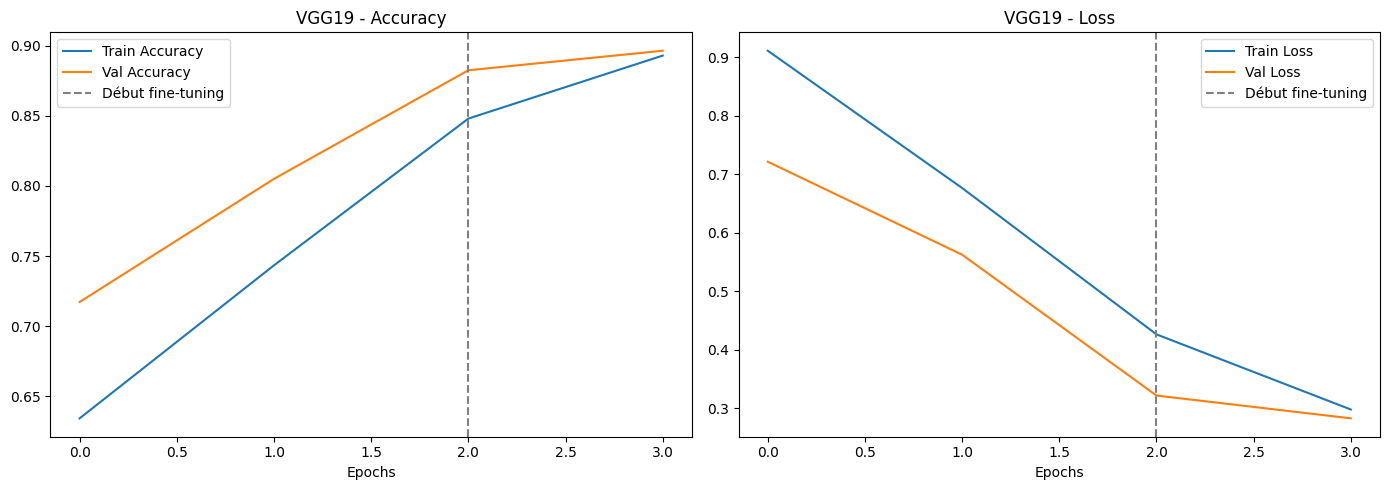

In [27]:
plot_finetuning_curves(history_vgg, 'VGG19'

In [30]:
eval_datagen = ImageDataGenerator(rescale=1./255)

eval_gen = eval_datagen.flow_from_dataframe(
    val_df,
    x_col='filepath',
    y_col='label',
    target_size=(224, 224),
    batch_size=32,
    class_mode='categorical',
    shuffle=False   # <-- ESSENTIEL pour l'évaluation
)

Found 4233 validated image filenames belonging to 4 classes.


133/133 ━━━━━━━━━━━━━━━━━━━━ 15s 111ms/step

Rapport de classification - VGG19
                 precision    recall  f1-score   support

          COVID       0.92      0.92      0.92       723
   Lung_Opacity       0.91      0.80      0.85      1203
         Normal       0.88      0.95      0.91      2038
Viral Pneumonia       0.97      0.86      0.91       269

       accuracy                           0.90      4233
      macro avg       0.92      0.88      0.90      4233
   weighted avg       0.90      0.90      0.90      4233



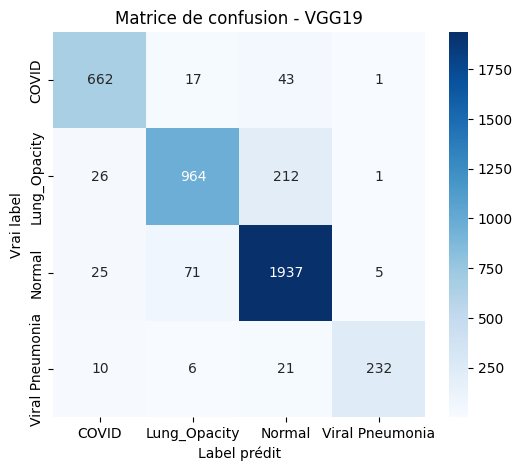

{'model': 'VGG19', 'accuracy': 0.8965272856130404, 'precision': 0.8984323452212497, 'recall': 0.8965272856130404, 'f1_score': 0.8955310486191193, 'auc': np.float64(0.98276300854093)}


In [31]:
metrics_vgg = evaluate_model(model_vgg, eval_gen, 'VGG19')
print(metrics_vgg)

In [11]:
import os
print(os.listdir('/kaggle/input/datasets/tawsifurrahman/covid19-radiography-database'))

['COVID-19_Radiography_Dataset']
